# Equidade das predicoes de obito entre subgrupos demograficos, teste de 2024

Este notebook avalia se a capacidade dos cinco algoritmos de discriminar o risco de obito por chikungunya varia entre subgrupos demograficos do teste de 2024.
As variaveis de estratificacao sao sexo, raca ou cor, e faixa etaria, as tres colunas demograficas usadas aqui a partir de `data/features/baseline/X_test.parquet`.
Para cada subgrupo e cada um dos cinco algoritmos ja treinados na fase de modelagem, a AUPRC e o ROC-AUC sao recalculados apenas sobre os casos daquele subgrupo, a partir das probabilidades preditas ja salvas em `output/metricas/`.
A medida central usada para comparar a equidade do desempenho do modelo entre subgrupos e a amplitude, a diferenca entre o subgrupo de maior e o subgrupo de menor metrica entre os subgrupos elegiveis de cada variavel, complementada por todas as diferencas par a par entre esses mesmos subgrupos elegiveis.
Essa comparacao nao usa nenhum subgrupo de referencia fixo, porque uma versao anterior desta analise usava um subgrupo de referencia escolhido por variavel sem um criterio consistente entre as tres variaveis, o que e detalhado com numeros reais mais adiante neste notebook.
Amplitude e diferencas par a par de AUPRC e de ROC-AUC, com intervalo de confianca de 95 por cento por bootstrap, sao calculadas apenas entre os subgrupos elegiveis de cada variavel, enquanto a largura do intervalo de confianca da ROC-AUC isolada de cada subgrupo, usada para decidir a elegibilidade, continua sendo calculada para todos os subgrupos, sem nenhum pre-filtro por numero de obitos.
A decisao de quais subgrupos entram na comparacao de disparidade usa um criterio separado, baseado na largura do intervalo de confianca de 95 por cento da propria ROC-AUC do subgrupo, exigida abaixo de uma largura-alvo nos cinco algoritmos ao mesmo tempo, detalhado na secao de incerteza amostral mais adiante.
Este notebook reporta apenas os numeros observados nos cinco algoritmos sobre o teste de 2024, sem nenhuma comparacao com valores de referencia externos a este estudo.

Importa as bibliotecas necessarias, define os diretorios de entrada e saida, e fixa a lista dos cinco algoritmos avaliados ao longo do notebook.
As tabelas de metricas por subgrupo sao salvas em `analysis/results_equidade/`, e os graficos de AUPRC por subgrupo elegivel sao salvos em `analysis/plots/equidade/`.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd().parent.parent
DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_equidade"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "equidade"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
METRICA_INDEFINIDA = "metrica indefinida: subgrupo com uma unica classe de desfecho"


Carrega as tres colunas demograficas do teste de 2024 a partir de `data/features/baseline/X_test.parquet`: sexo, raca ou cor, e idade em anos.
A idade em anos e convertida em cinco faixas etarias fixas, menor que 1 ano, de 1 a 17 anos, de 18 a 39 anos, de 40 a 59 anos, e 60 anos ou mais, a terceira variavel de estratificacao usada neste notebook.
Um caso sem idade registrada fica sem faixa etaria definida e e naturalmente excluido das tabelas por faixa etaria mais adiante, da mesma forma que os dois casos com sexo igual a "I", ignorado, sao excluidos da comparacao por sexo por serem uma amostra irrelevante.

In [2]:
COLUNAS_DEMOGRAFICAS = ["CS_SEXO", "CS_RACA", "IDADE_ANOS"]
LIMITES_FAIXA_ETARIA = [0, 1, 18, 40, 60, 105]
ROTULOS_FAIXA_ETARIA = ["<1", "1-17", "18-39", "40-59", "60+"]

covariaveis_teste2024 = pd.read_parquet(
    DIRETORIO_FEATURES / "X_test.parquet", columns=COLUNAS_DEMOGRAFICAS
).reset_index(drop=True)
covariaveis_teste2024["faixa_etaria"] = pd.cut(
    covariaveis_teste2024["IDADE_ANOS"],
    bins=LIMITES_FAIXA_ETARIA,
    labels=ROTULOS_FAIXA_ETARIA,
    right=False,
)

numero_registros_sem_faixa_etaria = covariaveis_teste2024["faixa_etaria"].isna().sum()
covariaveis_teste2024.shape, numero_registros_sem_faixa_etaria


((3978, 4), np.int64(1))

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real de obito ja salvos pela fase de modelagem para o teste de 2024.
Confirma que o alvo real e identico entre os cinco arquivos e que o numero de registros coincide com o das colunas demograficas carregadas na celula anterior, ja que ambos vem do mesmo conjunto de teste na mesma ordem posicional.
Concatena, para cada algoritmo, a tabela de predicoes com as colunas demograficas pela posicao da linha, criando uma unica tabela por algoritmo usada no restante do notebook.

In [3]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet"
    ).reset_index(drop=True)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis = len(covariaveis_teste2024)
alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
for algoritmo in ALGORITMOS:
    assert len(predicoes_teste2024[algoritmo]) == numero_registros_covariaveis
    assert np.array_equal(predicoes_teste2024[algoritmo]["obito"].to_numpy(), alvo_real_teste2024)

predicoes_com_covariaveis = {
    algoritmo: pd.concat([predicoes_teste2024[algoritmo], covariaveis_teste2024], axis=1)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis, int(alvo_real_teste2024.sum())


(3978, 208)

Define as tres variaveis de estratificacao analisadas neste notebook, sexo, raca ou cor, e faixa etaria, cada uma com seus subgrupos validos e os rotulos legiveis de cada subgrupo.
Nenhuma variavel tem um subgrupo de referencia fixo, pelos motivos detalhados com numeros reais mais adiante neste notebook, depois do calculo das metricas de incerteza amostral.
O codigo 9 de raca ou cor, rotulado ignorado, nao representa uma categoria racial, e qualquer diferenca de desempenho associada a ele deve ser lida como uma limitacao de qualidade do registro do dado, e nao como evidencia de equidade racial, ainda que receba o mesmo tratamento quantitativo dos demais subgrupos nesta analise.

In [4]:
ROTULOS_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indigena",
    "9": "Ignorado",
}

ESPECIFICACOES_ESTRATIFICACAO = [
    {
        "variavel_estratificacao": "sexo",
        "rotulo_variavel": "sexo",
        "coluna": "CS_SEXO",
        "subgrupos": ["F", "M"],
        "rotulos_subgrupo": {"F": "Feminino", "M": "Masculino"},
    },
    {
        "variavel_estratificacao": "raca_cor",
        "rotulo_variavel": "raca ou cor",
        "coluna": "CS_RACA",
        "subgrupos": ["1", "2", "3", "4", "5", "9"],
        "rotulos_subgrupo": ROTULOS_RACA_COR,
    },
    {
        "variavel_estratificacao": "faixa_etaria",
        "rotulo_variavel": "faixa etaria",
        "coluna": "faixa_etaria",
        "subgrupos": ROTULOS_FAIXA_ETARIA,
        "rotulos_subgrupo": {rotulo: rotulo for rotulo in ROTULOS_FAIXA_ETARIA},
    },
]

[especificacao["variavel_estratificacao"] for especificacao in ESPECIFICACOES_ESTRATIFICACAO]


['sexo', 'raca_cor', 'faixa_etaria']

Para cada variavel de estratificacao, cada algoritmo e cada subgrupo, calcula o numero de casos, o numero de obitos, a prevalencia observada de obito, a AUPRC e o ROC-AUC restritos aos casos daquele subgrupo, sem nenhum pre-filtro por numero de obitos.
A AUPRC e o ROC-AUC sao calculados com `average_precision_score` e `roc_auc_score` do scikit-learn, sobre a probabilidade predita e o desfecho real daquele algoritmo, apenas nas linhas do subgrupo em questao.
Um subgrupo em que todos os casos compartilham o mesmo desfecho, isto e, zero obitos ou obito em cem por cento dos casos, recebe o texto de metrica indefinida nessas colunas, porque a AUPRC e o ROC-AUC exigem matematicamente pelo menos um caso de cada classe para serem calculados, o que nao depende de nenhuma escolha metodologica.
A estabilidade da estimativa de cada subgrupo, incluindo os que tem poucos obitos mas ainda assim as duas classes presentes, e avaliada mais adiante neste notebook pela largura do intervalo de confianca de 95 por cento da ROC-AUC obtido por bootstrap, e nao por um limiar fixo de numero de eventos.

In [5]:
linhas_metricas_subgrupo = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        for subgrupo in especificacao["subgrupos"]:
            tabela_filtrada = tabela_algoritmo.loc[tabela_algoritmo[especificacao["coluna"]] == subgrupo]
            numero_registros = len(tabela_filtrada)
            numero_obitos = int(tabela_filtrada["obito"].sum())

            if numero_obitos == 0 or numero_obitos == numero_registros:
                auprc_subgrupo = METRICA_INDEFINIDA
                roc_auc_subgrupo = METRICA_INDEFINIDA
            else:
                auprc_subgrupo = average_precision_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )
                roc_auc_subgrupo = roc_auc_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )

            linhas_metricas_subgrupo.append(
                {
                    "variavel_estratificacao": especificacao["variavel_estratificacao"],
                    "subgrupo": especificacao["rotulos_subgrupo"][subgrupo],
                    "algoritmo": algoritmo,
                    "n": numero_registros,
                    "obitos": numero_obitos,
                    "prevalencia_obito": numero_obitos / numero_registros,
                    "auprc": auprc_subgrupo,
                    "roc_auc": roc_auc_subgrupo,
                }
            )

tabela_metricas_subgrupo = pd.DataFrame(linhas_metricas_subgrupo)
tabela_metricas_subgrupo


,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.227969,0.823805
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.209172,0.790043
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106632,0.745982
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.140518,0.691517
4,sexo,Feminino,random_forest,2196,90,0.040984,0.180106,0.822264
5,sexo,Masculino,random_forest,1780,118,0.066292,0.203019,0.780125
6,sexo,Feminino,xgboost,2196,90,0.040984,0.180951,0.776184
7,sexo,Masculino,xgboost,1780,118,0.066292,0.216019,0.746084
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.143,0.74417
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.191617,0.732434


Lista, de forma explicita, os subgrupos em que a AUPRC e o ROC-AUC sao matematicamente indefinidos, por reunirem uma unica classe de desfecho entre os casos observados.
Como essa condicao depende apenas da composicao do subgrupo, e nao do algoritmo, cada combinacao de variavel e subgrupo aparece aqui uma unica vez, mesmo tendo sido calculada para os cinco algoritmos na celula anterior.
Esses subgrupos sao diferentes dos subgrupos apenas instaveis, tratados mais adiante pelo criterio de largura de intervalo de confianca, porque nenhuma quantidade de reamostragem bootstrap resolve a ausencia completa de uma das duas classes de desfecho.

In [6]:
subgrupos_metrica_indefinida = (
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["auprc"].apply(lambda valor: isinstance(valor, str)),
        ["variavel_estratificacao", "subgrupo", "obitos"],
    ]
    .drop_duplicates()
    .sort_values(["variavel_estratificacao", "obitos"])
    .reset_index(drop=True)
)
subgrupos_metrica_indefinida


,variavel_estratificacao,subgrupo,obitos
0,raca_cor,Indigena,0


Salva a tabela de metricas por subgrupo em tres arquivos separados, um por variavel de estratificacao, em `analysis/results_equidade/`, para facilitar a leitura isolada de cada variavel.

In [7]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel
    ].to_csv(DIRETORIO_RESULTADOS_ANALISE / f"metricas_por_subgrupo_{nome_variavel}.csv", index=False)

sorted(caminho.name for caminho in DIRETORIO_RESULTADOS_ANALISE.glob("metricas_por_subgrupo_*.csv"))


['metricas_por_subgrupo_faixa_etaria.csv',
 'metricas_por_subgrupo_raca_cor.csv',
 'metricas_por_subgrupo_sexo.csv']

## Incerteza amostral das metricas por subgrupo, por bootstrap, e criterio de elegibilidade para a comparacao

As metricas de AUPRC e de ROC-AUC por subgrupo calculadas na secao anterior sao estimativas pontuais, calculadas uma unica vez sobre o teste de 2024, sem nenhuma medida de incerteza associada.
Entre rodadas recentes de retreino dos cinco algoritmos, motivadas por correcoes de features nao relacionadas a equidade, a direcao de varias diferencas entre subgrupos mudou de sinal, o que sugere que parte delas pode ser dominada por ruido amostral em vez de refletir uma diferenca real de desempenho entre subgrupos.
Esta secao estima, para todo subgrupo de toda variavel de estratificacao, sem nenhum pre-filtro por numero de obitos, um intervalo de confianca de 95 por cento por bootstrap da propria AUPRC e do proprio ROC-AUC de cada subgrupo, isoladamente, com o objetivo de, mais adiante, separar diferencas entre subgrupos estatisticamente distintas de zero de diferencas que podem ser inteiramente explicadas por variacao amostral.

Cada subgrupo e uma populacao de pacientes disjunta dos demais subgrupos da mesma variavel dentro do mesmo teste de 2024, de forma que o bootstrap usado aqui reamostra cada subgrupo isoladamente, com reposicao, no seu proprio tamanho, em cada iteracao.
Essa escolha segue a mesma convencao de numero de reamostragens e semente aleatoria do notebook de comparacao de algoritmos da fase de avaliacao, mas usa reamostragem de amostras independentes por subgrupo em vez de reamostragem pareada, porque os subgrupos aqui comparados, diferente dos algoritmos daquele notebook, nunca compartilham os mesmos pacientes.
Uma iteracao e descartada, apenas para o subgrupo em que isso ocorre, sempre que a reamostragem daquele subgrupo, nessa iteracao, nao contiver as duas classes de desfecho, caso em que AUPRC e ROC-AUC deixam de ser definidos.
Um subgrupo cuja amostra original, antes de qualquer reamostragem, ja reune uma unica classe de desfecho nunca passa esse teste em nenhuma iteracao, e o bootstrap e simplesmente pulado para ele, pelo mesmo motivo matematico da secao anterior.

Cada iteracao do bootstrap calcula tanto a AUPRC quanto a ROC-AUC da reamostragem daquele subgrupo, e as duas distribuicoes resultantes, uma por metrica, sao guardadas por subgrupo.
A distribuicao da ROC-AUC e usada primeiro, nesta secao, para estimar o intervalo de confianca de 95 por cento da ROC-AUC de cada subgrupo isolado, cuja largura e a medida de estabilidade estatistica usada para decidir, mais adiante, quais subgrupos entram na comparacao de disparidade, substituindo o limiar fixo de numero de obitos usado em versoes anteriores desta analise.
As duas distribuicoes, de AUPRC e de ROC-AUC, sao reaproveitadas novamente, sem nenhuma reamostragem adicional, depois que a elegibilidade de cada subgrupo estiver definida, para calcular as diferencas par a par e a amplitude entre os subgrupos elegiveis de cada variavel, nas secoes finais deste notebook.
A celula seguinte fixa o numero de reamostragens em 2000 e a semente aleatoria em 42, e cria o gerador de numeros aleatorios usado em todo o bootstrap deste notebook.

In [8]:
NUMERO_REAMOSTRAGENS = 2000
SEMENTE_ALEATORIA = 42
gerador_aleatorio = np.random.default_rng(SEMENTE_ALEATORIA)


A celula seguinte percorre todas as combinacoes de variavel de estratificacao, subgrupo e algoritmo, sem nenhum pre-filtro por numero de obitos, usando as mesmas probabilidades preditas e os mesmos alvos reais ja carregados em `predicoes_com_covariaveis`.
Para cada combinacao em que o subgrupo reune as duas classes de desfecho na amostra original, os indices daquele subgrupo sao reamostrados com reposicao, no seu proprio tamanho, em cada uma das 2000 iteracoes.
AUPRC e ROC-AUC sao recalculados sobre a reamostragem de cada iteracao, e as duas distribuicoes resultantes, uma de AUPRC e uma de ROC-AUC, sao guardadas por subgrupo em `distribuicoes_auprc_bootstrap_subgrupo` e em `distribuicoes_roc_auc_bootstrap_subgrupo`.
Uma iteracao especifica e descartada apenas da distribuicao daquele subgrupo quando a reamostragem dessa iteracao reune uma unica classe de desfecho, o que e extremamente raro para os subgrupos grandes e com obitos suficientes, e um subgrupo cuja amostra original reune uma unica classe de desfecho e inteiramente pulado, sem nenhuma iteracao, pelo mesmo motivo matematico da secao anterior.

In [9]:
distribuicoes_auprc_bootstrap_subgrupo = {}
distribuicoes_roc_auc_bootstrap_subgrupo = {}

for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    coluna = especificacao["coluna"]

    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]

        for codigo_subgrupo in especificacao["subgrupos"]:
            rotulo_subgrupo = especificacao["rotulos_subgrupo"][codigo_subgrupo]
            tabela_subgrupo = tabela_algoritmo.loc[tabela_algoritmo[coluna] == codigo_subgrupo]
            alvo_subgrupo = tabela_subgrupo["obito"].to_numpy()
            probabilidade_subgrupo = tabela_subgrupo["probabilidade_predita"].to_numpy()
            numero_registros_subgrupo = len(alvo_subgrupo)
            numero_obitos_subgrupo = int(alvo_subgrupo.sum())
            subgrupo_tem_as_duas_classes = 0 < numero_obitos_subgrupo < numero_registros_subgrupo

            if not subgrupo_tem_as_duas_classes:
                continue

            auprc_bootstrap_subgrupo = []
            roc_auc_bootstrap_subgrupo = []
            for _ in range(NUMERO_REAMOSTRAGENS):
                indices_reamostrados = gerador_aleatorio.integers(
                    low=0, high=numero_registros_subgrupo, size=numero_registros_subgrupo
                )
                alvo_reamostrado = alvo_subgrupo[indices_reamostrados]

                if not (0 < alvo_reamostrado.sum() < numero_registros_subgrupo):
                    continue

                probabilidade_reamostrada = probabilidade_subgrupo[indices_reamostrados]
                auprc_bootstrap_subgrupo.append(
                    average_precision_score(alvo_reamostrado, probabilidade_reamostrada)
                )
                roc_auc_bootstrap_subgrupo.append(
                    roc_auc_score(alvo_reamostrado, probabilidade_reamostrada)
                )

            chave_subgrupo = (nome_variavel, rotulo_subgrupo, algoritmo)
            distribuicoes_auprc_bootstrap_subgrupo[chave_subgrupo] = np.array(auprc_bootstrap_subgrupo)
            distribuicoes_roc_auc_bootstrap_subgrupo[chave_subgrupo] = np.array(roc_auc_bootstrap_subgrupo)

len(distribuicoes_roc_auc_bootstrap_subgrupo), len(distribuicoes_auprc_bootstrap_subgrupo)


(60, 60)

Para cada subgrupo e cada algoritmo, esta celula reaproveita a distribuicao bootstrap da ROC-AUC isolada guardada em `distribuicoes_roc_auc_bootstrap_subgrupo` para estimar o intervalo de confianca de 95 por cento da propria ROC-AUC daquele subgrupo, sem executar nenhum bootstrap adicional.
A largura do intervalo, limite superior menos limite inferior, e calculada para cada combinacao de variavel, subgrupo e algoritmo, e sera a base do criterio de elegibilidade para a comparacao de disparidade definido nas celulas seguintes.
Subgrupos sem distribuicao disponivel, por reunirem uma unica classe de desfecho na amostra original, recebem intervalo e largura ausentes, em vez de um numero.
A tabela resultante e ordenada pelo numero de obitos do subgrupo, para deixar visivel a relacao entre numero de obitos e largura do intervalo de confianca, e e salva em `analysis/results_equidade/largura_ic_roc_auc_por_subgrupo.csv`.

In [10]:
linhas_largura_ic_roc_auc = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    for algoritmo in ALGORITMOS:
        for codigo_subgrupo in especificacao["subgrupos"]:
            rotulo_subgrupo = especificacao["rotulos_subgrupo"][codigo_subgrupo]
            linha_metrica = tabela_metricas_subgrupo.loc[
                (tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel)
                & (tabela_metricas_subgrupo["subgrupo"] == rotulo_subgrupo)
                & (tabela_metricas_subgrupo["algoritmo"] == algoritmo)
            ].iloc[0]

            distribuicao_bootstrap = distribuicoes_roc_auc_bootstrap_subgrupo.get(
                (nome_variavel, rotulo_subgrupo, algoritmo)
            )
            if distribuicao_bootstrap is None or len(distribuicao_bootstrap) == 0:
                roc_auc_ic95_inferior = np.nan
                roc_auc_ic95_superior = np.nan
                largura_ic_roc_auc = np.nan
            else:
                roc_auc_ic95_inferior = np.percentile(distribuicao_bootstrap, 2.5)
                roc_auc_ic95_superior = np.percentile(distribuicao_bootstrap, 97.5)
                largura_ic_roc_auc = roc_auc_ic95_superior - roc_auc_ic95_inferior

            linhas_largura_ic_roc_auc.append(
                {
                    "variavel_estratificacao": nome_variavel,
                    "subgrupo": rotulo_subgrupo,
                    "algoritmo": algoritmo,
                    "n": int(linha_metrica["n"]),
                    "obitos": int(linha_metrica["obitos"]),
                    "roc_auc": linha_metrica["roc_auc"],
                    "roc_auc_ic95_inferior": roc_auc_ic95_inferior,
                    "roc_auc_ic95_superior": roc_auc_ic95_superior,
                    "largura_ic_roc_auc": largura_ic_roc_auc,
                }
            )

tabela_largura_ic_roc_auc_subgrupo = pd.DataFrame(linhas_largura_ic_roc_auc).sort_values(
    ["obitos", "variavel_estratificacao", "subgrupo", "algoritmo"]
).reset_index(drop=True)

tabela_largura_ic_roc_auc_subgrupo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "largura_ic_roc_auc_por_subgrupo.csv", index=False
)

tabela_largura_ic_roc_auc_subgrupo


,variavel_estratificacao,subgrupo,algoritmo,n,obitos,roc_auc,roc_auc_ic95_inferior,roc_auc_ic95_superior,largura_ic_roc_auc
0,raca_cor,Indigena,arvore_decisao,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
1,raca_cor,Indigena,lightgbm,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
2,raca_cor,Indigena,random_forest,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
3,raca_cor,Indigena,regressao_logistica,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
4,raca_cor,Indigena,xgboost,13,0,metrica indefinida: subgrupo com uma unica cla...,NaN,NaN,NaN
5,raca_cor,Amarela,arvore_decisao,42,2,0.31875,0.000000,0.719512,0.719512
6,raca_cor,Amarela,lightgbm,42,2,0.775,0.575000,0.950000,0.375000
7,raca_cor,Amarela,random_forest,42,2,0.5125,0.170732,0.853659,0.682927
8,raca_cor,Amarela,regressao_logistica,42,2,0.6625,0.341463,0.926829,0.585366
9,raca_cor,Amarela,xgboost,42,2,0.425,0.243902,0.625000,0.381098


Antes de fixar a largura-alvo usada no restante do notebook, esta celula testa quatro larguras candidatas sobre a tabela real de larguras de intervalo de confianca da celula anterior, para apoiar a escolha final.
Para cada largura candidata, um subgrupo e considerado elegivel quando a maior largura de intervalo de confianca de ROC-AUC entre os cinco algoritmos fica abaixo da largura candidata, a mesma regra de elegivel nos cinco modelos ao mesmo tempo usada na analise principal.
A tabela reporta, para cada variavel de estratificacao e cada largura candidata, quantos subgrupos ficam elegiveis e o total de subgrupos daquela variavel.
O resultado e salvo em `analysis/results_equidade/sensibilidade_largura_alvo_roc_auc.csv` para referencia futura.

In [11]:
LARGURAS_ALVO_TESTADAS = [0.15, 0.20, 0.35, 0.55]

largura_maxima_por_subgrupo_todas_variaveis = (
    tabela_largura_ic_roc_auc_subgrupo.groupby(["variavel_estratificacao", "subgrupo"])["largura_ic_roc_auc"]
    .max()
    .rename("largura_ic_roc_auc_maxima_entre_modelos")
    .reset_index()
)

linhas_sensibilidade = []
for largura_alvo_testada in LARGURAS_ALVO_TESTADAS:
    avaliacao = largura_maxima_por_subgrupo_todas_variaveis.copy()
    avaliacao["elegivel"] = avaliacao["largura_ic_roc_auc_maxima_entre_modelos"] < largura_alvo_testada

    linha_sensibilidade = {"largura_alvo_roc_auc_testada": largura_alvo_testada}
    for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
        nome_variavel = especificacao["variavel_estratificacao"]
        avaliacao_variavel = avaliacao.loc[avaliacao["variavel_estratificacao"] == nome_variavel]

        linha_sensibilidade[f"{nome_variavel}_elegiveis"] = int(avaliacao_variavel["elegivel"].sum())
        linha_sensibilidade[f"{nome_variavel}_total"] = int(len(avaliacao_variavel))

    linhas_sensibilidade.append(linha_sensibilidade)

tabela_sensibilidade_largura_alvo = pd.DataFrame(linhas_sensibilidade)
tabela_sensibilidade_largura_alvo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "sensibilidade_largura_alvo_roc_auc.csv", index=False
)
tabela_sensibilidade_largura_alvo


,largura_alvo_roc_auc_testada,sexo_elegiveis,sexo_total,raca_cor_elegiveis,raca_cor_total,faixa_etaria_elegiveis,faixa_etaria_total
0,0.15,2,2,2,6,1,5
1,0.20,2,2,2,6,2,5
2,0.35,2,2,2,6,3,5
3,0.55,2,2,3,6,4,5


### Escolha da largura-alvo

A tabela real de larguras de intervalo de confianca mostra uma separacao em tres faixas de estabilidade, visivel na coluna `largura_ic_roc_auc_maxima_entre_modelos`.
Um primeiro grupo de cinco subgrupos, 60 anos ou mais, Parda, Feminino, Masculino e Branca, tem a maior largura entre os cinco algoritmos sempre abaixo de 0,13, entre 0,095 e 0,125.
Um segundo grupo, formado por 40 a 59 anos e por 18 a 39 anos, tem largura maxima entre 0,197 e 0,294.
Um terceiro grupo de subgrupos pequenos, Ignorado, 1 a 17 anos, Preta, menor que 1 ano e Amarela, tem largura maxima entre 0,502 e 0,720, e Indigena nao tem largura definida por reunir zero obitos.
O maior salto entre subgrupos consecutivos nessa ordenacao acontece exatamente entre o segundo e o terceiro grupo, da largura maxima de 18 a 39 anos, 0,294, para a largura maxima de Ignorado, 0,502, uma diferenca de 0,208, bem maior do que qualquer outro salto da tabela.

A largura-alvo escolhida para o restante deste notebook e 0,35 de ROC-AUC.
Esse valor fica dentro do grande intervalo vazio entre 0,294 e 0,502 identificado na tabela real, com margem confortavel para os dois lados, e esta bem distante de 0,5, que corresponderia a cobrir quase toda a faixa plausivel de ROC-AUC, de 0,5 a 1,0.
Com essa largura-alvo, a tabela de sensibilidade mostra que sexo mantem os dois subgrupos elegiveis, Feminino e Masculino, raca ou cor mantem dois subgrupos elegiveis, Branca e Parda, e faixa etaria passa a ter tres subgrupos elegiveis, 18 a 39 anos, 40 a 59 anos e 60 anos ou mais.

As larguras-alvo mais restritivas testadas na tabela de sensibilidade, 0,15 e 0,20, ilustram por que um criterio restritivo demais e inadequado aqui.
Com largura-alvo de 0,15, apenas um subgrupo de faixa etaria fica elegivel, 60 anos ou mais, o que inviabilizaria qualquer comparacao dentro dessa variavel, e com largura-alvo de 0,20, apenas dois dos tres subgrupos ficam elegiveis, 40 a 59 anos e 60 anos ou mais, porque a faixa de 18 a 39 anos so fica elegivel a partir de uma largura-alvo acima de 0,294.
A largura-alvo menos restritiva testada, 0,55, mostra o inicio da inclusao do proximo grupo de subgrupos pequenos, Ignorado em raca ou cor e 1 a 17 anos em faixa etaria, sem ainda se aproximar do limite superior plausivel da ROC-AUC.

Os seis subgrupos excluidos pelo criterio antigo de menos de 10 obitos, menor que 1 ano, 1 a 17 anos, Amarela, Ignorado, Indigena e Preta, permanecem todos nao elegiveis com a largura-alvo de 0,35, cada um com largura maxima de intervalo de confianca de ROC-AUC acima de 0,50, bem distante do grupo elegivel.
O conjunto final de subgrupos elegiveis para a comparacao de disparidade e, portanto, o mesmo que o criterio antigo produzia, Feminino e Masculino em sexo, Branca e Parda em raca ou cor, e 18 a 39 anos, 40 a 59 anos e 60 anos ou mais em faixa etaria.
A diferenca e que esse conjunto agora decorre de uma regra uniforme, aplicada aos cinco algoritmos ao mesmo tempo e verificavel diretamente nos numeros observados de largura de intervalo de confianca, em vez de um numero fixo de obitos escolhido sem relacao com o comportamento estatistico da propria metrica.

In [12]:
LARGURA_ALVO_ROC_AUC = 0.35

largura_maxima_por_subgrupo = (
    tabela_largura_ic_roc_auc_subgrupo.groupby(["variavel_estratificacao", "subgrupo"])["largura_ic_roc_auc"]
    .max()
    .rename("largura_ic_roc_auc_maxima_entre_modelos")
    .reset_index()
)
largura_maxima_por_subgrupo["elegivel_comparacao"] = (
    largura_maxima_por_subgrupo["largura_ic_roc_auc_maxima_entre_modelos"] < LARGURA_ALVO_ROC_AUC
)

tabela_largura_ic_roc_auc_subgrupo = tabela_largura_ic_roc_auc_subgrupo.merge(
    largura_maxima_por_subgrupo, on=["variavel_estratificacao", "subgrupo"], how="left"
)
tabela_largura_ic_roc_auc_subgrupo.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "largura_ic_roc_auc_por_subgrupo.csv", index=False
)

contagem_elegiveis_por_variavel = largura_maxima_por_subgrupo.groupby("variavel_estratificacao").agg(
    subgrupos_elegiveis=("elegivel_comparacao", "sum"), total_subgrupos=("elegivel_comparacao", "size")
)
contagem_elegiveis_por_variavel


,subgrupos_elegiveis,total_subgrupos
variavel_estratificacao,,
faixa_etaria,3,5
raca_cor,2,6
sexo,2,2


Consolida, numa unica tabela longa, o numero de casos, o numero de obitos, a prevalencia de obito, a AUPRC e o ROC-AUC pontuais de cada subgrupo, o intervalo de confianca de 95 por cento de cada uma dessas duas metricas, reaproveitado das distribuicoes bootstrap calculadas por subgrupo isolado, e a marcacao de elegibilidade para a comparacao de disparidade.
Esta tabela nao depende de nenhum subgrupo de referencia, porque cada linha descreve um unico subgrupo isoladamente, e e salva em `analysis/results_equidade/tabela_equidade_consolidada.csv`.
Nenhuma linha e removida desta tabela, incluindo os subgrupos nao elegiveis para a comparacao de disparidade, para que o numero de casos, o numero de obitos, e a estimativa pontual e o intervalo de confianca de todos os subgrupos continuem disponiveis para consulta.

In [13]:
def intervalo_confianca_bootstrap(distribuicao):
    if distribuicao is None or len(distribuicao) == 0:
        return np.nan, np.nan
    return np.percentile(distribuicao, 2.5), np.percentile(distribuicao, 97.5)


linhas_equidade_consolidada = []
for _, linha in tabela_metricas_subgrupo.iterrows():
    chave_subgrupo = (linha["variavel_estratificacao"], linha["subgrupo"], linha["algoritmo"])
    auprc_ic95_inferior, auprc_ic95_superior = intervalo_confianca_bootstrap(
        distribuicoes_auprc_bootstrap_subgrupo.get(chave_subgrupo)
    )
    roc_auc_ic95_inferior, roc_auc_ic95_superior = intervalo_confianca_bootstrap(
        distribuicoes_roc_auc_bootstrap_subgrupo.get(chave_subgrupo)
    )
    linhas_equidade_consolidada.append(
        {
            "variavel_estratificacao": linha["variavel_estratificacao"],
            "subgrupo": linha["subgrupo"],
            "algoritmo": linha["algoritmo"],
            "n": linha["n"],
            "obitos": linha["obitos"],
            "prevalencia_obito": linha["prevalencia_obito"],
            "auprc": linha["auprc"],
            "auprc_ic95_inferior": auprc_ic95_inferior,
            "auprc_ic95_superior": auprc_ic95_superior,
            "roc_auc": linha["roc_auc"],
            "roc_auc_ic95_inferior": roc_auc_ic95_inferior,
            "roc_auc_ic95_superior": roc_auc_ic95_superior,
        }
    )

tabela_equidade_consolidada = pd.DataFrame(linhas_equidade_consolidada).merge(
    largura_maxima_por_subgrupo[["variavel_estratificacao", "subgrupo", "elegivel_comparacao"]],
    on=["variavel_estratificacao", "subgrupo"],
    how="left",
)

tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)

tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(drop=True)


,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,auprc_ic95_inferior,auprc_ic95_superior,roc_auc,roc_auc_ic95_inferior,roc_auc_ic95_superior,elegivel_comparacao
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,0.012788,0.002778,0.025620,0.681647,0.515989,0.774140,False
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,0.010861,0.003714,0.039645,0.527778,0.260203,0.805036,False
2,faixa_etaria,1-17,random_forest,846,6,0.007092,0.009672,0.003414,0.024807,0.552579,0.268358,0.763810,False
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,0.015836,0.006230,0.035861,0.699206,0.453249,0.845996,False
4,faixa_etaria,1-17,xgboost,846,6,0.007092,0.009244,0.003467,0.023712,0.535317,0.263435,0.772426,False
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.033318,0.016600,0.056250,0.676018,0.562597,0.791538,True
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.04973,0.022900,0.115347,0.668561,0.520807,0.800929,True
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.045544,0.025268,0.100223,0.739029,0.632721,0.831763,True
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.113552,0.037658,0.301299,0.775944,0.647897,0.883285,True
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.033711,0.017085,0.074623,0.591217,0.439916,0.733944,True


### Por que a comparacao deixa de usar um subgrupo de referencia fixo

Uma versao anterior desta analise comparava cada subgrupo elegivel contra um subgrupo de referencia fixo por variavel, feminino para sexo, branca para raca ou cor, e a faixa de 18 a 39 anos para faixa etaria.
Para faixa etaria, essa escolha seguia uma regra declarada, a faixa com a menor prevalencia observada de obito entre as faixas elegiveis, e a faixa de 18 a 39 anos de fato tem a menor prevalencia entre as tres faixas elegiveis, 1,94 por cento, contra 3,99 por cento na faixa de 40 a 59 anos e 11,85 por cento na faixa de 60 anos ou mais.
Para sexo e raca ou cor, o codigo nao declarava nenhuma regra, apenas um valor fixo, e testar se a mesma regra de menor prevalencia valeria para essas duas variaveis revela uma inconsistencia.
Em sexo, a regra bateria por coincidencia, porque o feminino, subgrupo de referencia escolhido, tem prevalencia de obito de 4,10 por cento, menor do que os 6,63 por cento do masculino.
Em raca ou cor, a regra nao bate, porque a branca, subgrupo de referencia escolhido, tem a maior prevalencia de obito entre as duas categorias elegiveis, 7,09 por cento, contra 5,07 por cento da parda, o oposto do que a regra de menor prevalencia usada para faixa etaria exigiria.
Isso significa que a branca foi usada como referencia de raca ou cor sem nenhuma justificativa consistente com o criterio realmente aplicado as outras variaveis, e qualquer delta calculado contra ela carregava essa escolha arbitraria.
A correcao adotada neste notebook elimina a necessidade de escolher qualquer subgrupo de referencia: em vez de um delta contra uma referencia, a medida central passa a ser a amplitude entre o subgrupo de maior e o subgrupo de menor metrica entre os subgrupos elegiveis de cada variavel, acompanhada de todas as diferencas par a par entre esses subgrupos, cada uma com o proprio intervalo de confianca por bootstrap.
Maior metrica e menor metrica saem diretamente dos dados observados em cada variavel, sem nenhuma escolha a priori de qual subgrupo deveria servir de base de comparacao.

### Ressalva sobre AUPRC e prevalencia de obito

A AUPRC tem a prevalencia da classe positiva como piso teorico, um classificador sem nenhuma capacidade de discriminacao tem AUPRC esperada igual a propria prevalencia de obito do subgrupo, nao zero, ao contrario do ROC-AUC, cujo piso de referencia e sempre 0,5 independentemente da prevalencia.
Isso e uma propriedade conhecida da metrica, decorrente da sua definicao matematica, e nao um achado deste estudo.
Por isso, uma AUPRC mais alta num subgrupo de maior prevalencia de obito pode refletir, ao menos em parte, essa diferenca de piso teorico, e nao necessariamente uma diferenca real na capacidade do modelo de ordenar corretamente os casos daquele subgrupo por risco.
Essa ressalva e particularmente relevante para faixa etaria neste estudo, cujos subgrupos elegiveis tem prevalencia de obito bastante diferente entre si, e deve ser considerada ao interpretar qualquer amplitude ou diferenca de AUPRC entre subgrupos de prevalencia muito diferente, incluindo as reportadas na secao seguinte.

Para cada variavel de estratificacao, cada algoritmo e cada uma das duas metricas, AUPRC e ROC-AUC, esta celula calcula todas as diferencas par a par entre os subgrupos elegiveis daquela variavel, a partir da coluna `elegivel_comparacao` ja calculada, sem favorecer nenhum subgrupo como base de comparacao.
Cada diferenca par a par reaproveita as distribuicoes bootstrap por subgrupo isolado ja calculadas, subtraindo, posicao a posicao, a distribuicao reamostrada de um subgrupo da distribuicao reamostrada do outro, sem nenhuma reamostragem nova, o mesmo principio estatistico de bootstrap de duas amostras independentes usado na versao anterior desta analise.
O intervalo de confianca de 95 por cento de cada diferenca usa os percentis 2,5 e 97,5 dessa distribuicao de diferencas, e a diferenca e marcada como significativa quando esse intervalo exclui zero, o mesmo criterio ja usado neste notebook.
Sexo e raca ou cor tem dois subgrupos elegiveis cada, logo um unico par por variavel, enquanto faixa etaria tem tres subgrupos elegiveis, logo tres pares, 18 a 39 contra 40 a 59, 18 a 39 contra 60 ou mais, e 40 a 59 contra 60 ou mais.
O resultado e salvo em `analysis/results_equidade/comparacoes_par_a_par.csv`.

In [14]:
conjunto_subgrupos_elegiveis = {
    nome_variavel: set(tabela_variavel.loc[tabela_variavel["elegivel_comparacao"], "subgrupo"])
    for nome_variavel, tabela_variavel in largura_maxima_por_subgrupo.groupby("variavel_estratificacao")
}

linhas_comparacoes_par_a_par = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    subgrupos_elegiveis_ordenados = [
        especificacao["rotulos_subgrupo"][codigo_subgrupo]
        for codigo_subgrupo in especificacao["subgrupos"]
        if especificacao["rotulos_subgrupo"][codigo_subgrupo]
        in conjunto_subgrupos_elegiveis.get(nome_variavel, set())
    ]

    for algoritmo in ALGORITMOS:
        linha_metrica_ponto = tabela_metricas_subgrupo.loc[
            (tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel)
            & (tabela_metricas_subgrupo["algoritmo"] == algoritmo)
        ]

        for metrica, distribuicoes_bootstrap_metrica in [
            ("auprc", distribuicoes_auprc_bootstrap_subgrupo),
            ("roc_auc", distribuicoes_roc_auc_bootstrap_subgrupo),
        ]:
            for subgrupo_1, subgrupo_2 in combinations(subgrupos_elegiveis_ordenados, 2):
                distribuicao_1 = distribuicoes_bootstrap_metrica[(nome_variavel, subgrupo_1, algoritmo)]
                distribuicao_2 = distribuicoes_bootstrap_metrica[(nome_variavel, subgrupo_2, algoritmo)]
                numero_iteracoes_comuns = min(len(distribuicao_1), len(distribuicao_2))
                distribuicao_diferenca = (
                    distribuicao_1[:numero_iteracoes_comuns] - distribuicao_2[:numero_iteracoes_comuns]
                )

                ic95_inferior = np.percentile(distribuicao_diferenca, 2.5)
                ic95_superior = np.percentile(distribuicao_diferenca, 97.5)

                valor_ponto_1 = linha_metrica_ponto.loc[linha_metrica_ponto["subgrupo"] == subgrupo_1, metrica].iloc[0]
                valor_ponto_2 = linha_metrica_ponto.loc[linha_metrica_ponto["subgrupo"] == subgrupo_2, metrica].iloc[0]

                linhas_comparacoes_par_a_par.append(
                    {
                        "variavel_estratificacao": nome_variavel,
                        "subgrupo_1": subgrupo_1,
                        "subgrupo_2": subgrupo_2,
                        "algoritmo": algoritmo,
                        "metrica": metrica,
                        "diferenca_pontual": float(valor_ponto_1) - float(valor_ponto_2),
                        "diferenca_ic95_inferior": ic95_inferior,
                        "diferenca_ic95_superior": ic95_superior,
                        "numero_iteracoes_comuns": numero_iteracoes_comuns,
                        "significativa": bool(ic95_inferior * ic95_superior > 0),
                    }
                )

tabela_comparacoes_par_a_par = pd.DataFrame(linhas_comparacoes_par_a_par)
tabela_comparacoes_par_a_par.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "comparacoes_par_a_par.csv", index=False
)
tabela_comparacoes_par_a_par


,variavel_estratificacao,subgrupo_1,subgrupo_2,algoritmo,metrica,diferenca_pontual,diferenca_ic95_inferior,diferenca_ic95_superior,numero_iteracoes_comuns,significativa
0,sexo,Feminino,Masculino,regressao_logistica,auprc,0.018797,-0.085261,0.128163,2000,False
1,sexo,Feminino,Masculino,regressao_logistica,roc_auc,0.033762,-0.025232,0.094803,2000,False
2,sexo,Feminino,Masculino,arvore_decisao,auprc,-0.033886,-0.080159,0.016677,2000,False
3,sexo,Feminino,Masculino,arvore_decisao,roc_auc,0.054466,-0.022535,0.131924,2000,False
4,sexo,Feminino,Masculino,random_forest,auprc,-0.022913,-0.110716,0.066744,2000,False
5,sexo,Feminino,Masculino,random_forest,roc_auc,0.042139,-0.015051,0.104274,2000,False
6,sexo,Feminino,Masculino,xgboost,auprc,-0.035068,-0.129557,0.073648,2000,False
7,sexo,Feminino,Masculino,xgboost,roc_auc,0.030100,-0.039228,0.101066,2000,False
8,sexo,Feminino,Masculino,lightgbm,auprc,-0.048617,-0.128674,0.035084,2000,False
9,sexo,Feminino,Masculino,lightgbm,roc_auc,0.011736,-0.061084,0.084231,2000,False


Para cada variavel de estratificacao, cada algoritmo e cada uma das duas metricas, esta celula calcula a amplitude entre o subgrupo de maior e o subgrupo de menor metrica, considerando apenas os subgrupos elegiveis daquela variavel.
O subgrupo de maior e o subgrupo de menor metrica sao identificados a partir do ponto estimado, sem nenhuma reamostragem, e a amplitude pontual e a diferenca entre esses dois valores observados.
O intervalo de confianca da amplitude reaproveita as mesmas distribuicoes bootstrap por subgrupo isolado, em cada uma das iteracoes, toma o maior e o menor valor reamostrado entre os subgrupos elegiveis daquela variavel nessa iteracao, calcula a diferenca entre os dois, e empilha essas diferencas numa distribuicao bootstrap da amplitude, cujos percentis 2,5 e 97,5 formam o intervalo de confianca de 95 por cento.
Como a amplitude e sempre maior ou igual a zero por construcao, o criterio de significancia, intervalo de confianca que exclui zero, tende a ser satisfeito com mais facilidade pela amplitude do que pela diferenca par a par com sinal da celula anterior, e por isso a comparacao par a par, nao a amplitude, deve ser a referencia principal para decidir se dois subgrupos especificos diferem entre si.
O resultado e salvo em `analysis/results_equidade/amplitude_por_variavel.csv`.

In [15]:
linhas_amplitude_por_variavel = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    subgrupos_elegiveis_ordenados = [
        especificacao["rotulos_subgrupo"][codigo_subgrupo]
        for codigo_subgrupo in especificacao["subgrupos"]
        if especificacao["rotulos_subgrupo"][codigo_subgrupo]
        in conjunto_subgrupos_elegiveis.get(nome_variavel, set())
    ]

    for algoritmo in ALGORITMOS:
        linha_metrica_ponto = tabela_metricas_subgrupo.loc[
            (tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel)
            & (tabela_metricas_subgrupo["algoritmo"] == algoritmo)
            & (tabela_metricas_subgrupo["subgrupo"].isin(subgrupos_elegiveis_ordenados))
        ]

        for metrica, distribuicoes_bootstrap_metrica in [
            ("auprc", distribuicoes_auprc_bootstrap_subgrupo),
            ("roc_auc", distribuicoes_roc_auc_bootstrap_subgrupo),
        ]:
            valores_pontuais = linha_metrica_ponto.set_index("subgrupo")[metrica].astype(float)
            subgrupo_maior = valores_pontuais.idxmax()
            subgrupo_menor = valores_pontuais.idxmin()
            amplitude_pontual = valores_pontuais[subgrupo_maior] - valores_pontuais[subgrupo_menor]

            comprimento_comum = min(
                len(distribuicoes_bootstrap_metrica[(nome_variavel, subgrupo, algoritmo)])
                for subgrupo in subgrupos_elegiveis_ordenados
            )
            matriz_bootstrap_subgrupos = np.vstack(
                [
                    distribuicoes_bootstrap_metrica[(nome_variavel, subgrupo, algoritmo)][:comprimento_comum]
                    for subgrupo in subgrupos_elegiveis_ordenados
                ]
            )
            distribuicao_amplitude = matriz_bootstrap_subgrupos.max(axis=0) - matriz_bootstrap_subgrupos.min(axis=0)

            ic95_inferior = np.percentile(distribuicao_amplitude, 2.5)
            ic95_superior = np.percentile(distribuicao_amplitude, 97.5)

            linhas_amplitude_por_variavel.append(
                {
                    "variavel_estratificacao": nome_variavel,
                    "algoritmo": algoritmo,
                    "metrica": metrica,
                    "subgrupo_maior": subgrupo_maior,
                    "subgrupo_menor": subgrupo_menor,
                    "amplitude_pontual": amplitude_pontual,
                    "amplitude_ic95_inferior": ic95_inferior,
                    "amplitude_ic95_superior": ic95_superior,
                    "significativa": bool(ic95_inferior * ic95_superior > 0),
                }
            )

tabela_amplitude_por_variavel = pd.DataFrame(linhas_amplitude_por_variavel)
tabela_amplitude_por_variavel.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "amplitude_por_variavel.csv", index=False
)
tabela_amplitude_por_variavel


,variavel_estratificacao,algoritmo,metrica,subgrupo_maior,subgrupo_menor,amplitude_pontual,amplitude_ic95_inferior,amplitude_ic95_superior,significativa
0,sexo,regressao_logistica,auprc,Feminino,Masculino,0.018797,0.001457,0.129369,True
1,sexo,regressao_logistica,roc_auc,Feminino,Masculino,0.033762,0.001851,0.094803,True
2,sexo,arvore_decisao,auprc,Masculino,Feminino,0.033886,0.001802,0.080159,True
3,sexo,arvore_decisao,roc_auc,Feminino,Masculino,0.054466,0.003143,0.131924,True
4,sexo,random_forest,auprc,Masculino,Feminino,0.022913,0.001364,0.111263,True
5,sexo,random_forest,roc_auc,Feminino,Masculino,0.042139,0.002536,0.104274,True
6,sexo,xgboost,auprc,Masculino,Feminino,0.035068,0.002355,0.129630,True
7,sexo,xgboost,roc_auc,Feminino,Masculino,0.030100,0.002005,0.101066,True
8,sexo,lightgbm,auprc,Masculino,Feminino,0.048617,0.002069,0.128674,True
9,sexo,lightgbm,roc_auc,Feminino,Masculino,0.011736,0.001223,0.086720,True


Para cada variavel de estratificacao, gera um grafico que mostra a AUPRC observada de cada subgrupo elegivel, com intervalo de confianca de 95 por cento, uma cor por algoritmo, sem nenhum subgrupo de referencia.
Os pares de subgrupos cuja diferenca de AUPRC e estatisticamente significativa, segundo a tabela de comparacoes par a par, recebem uma chave horizontal ligando os dois subgrupos, na cor do algoritmo correspondente, com um asterisco, empilhada verticalmente quando mais de um algoritmo e significativo para o mesmo par.
O titulo de cada grafico deixa explicito que a figura mostra uma comparacao par a par entre os subgrupos elegiveis daquela variavel, e nao mais uma diferenca contra um subgrupo de referencia.
Os tres graficos sao salvos em `analysis/plots/equidade/`, um arquivo por variavel de estratificacao, com os nomes `auprc_por_subgrupo_sexo.png`, `auprc_por_subgrupo_raca_cor.png` e `auprc_por_subgrupo_faixa_etaria.png`.

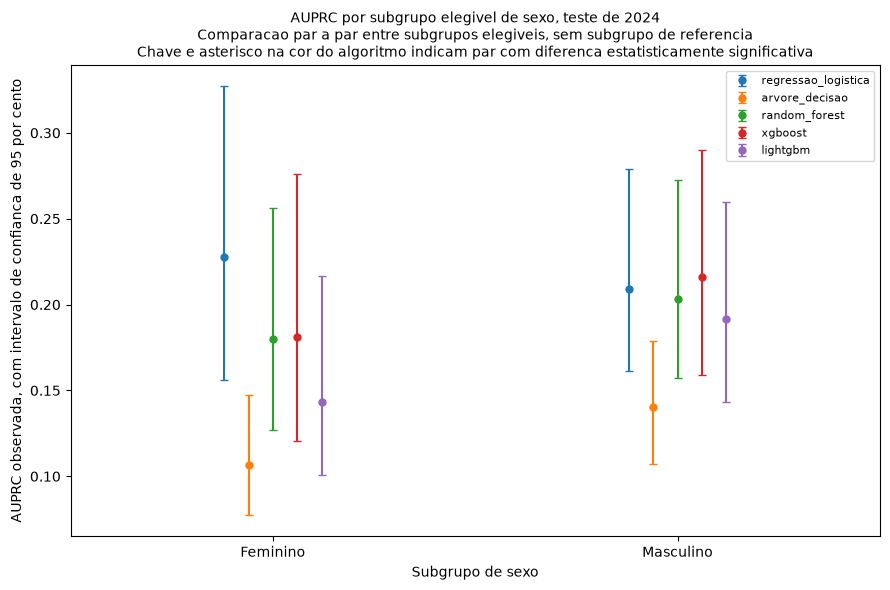

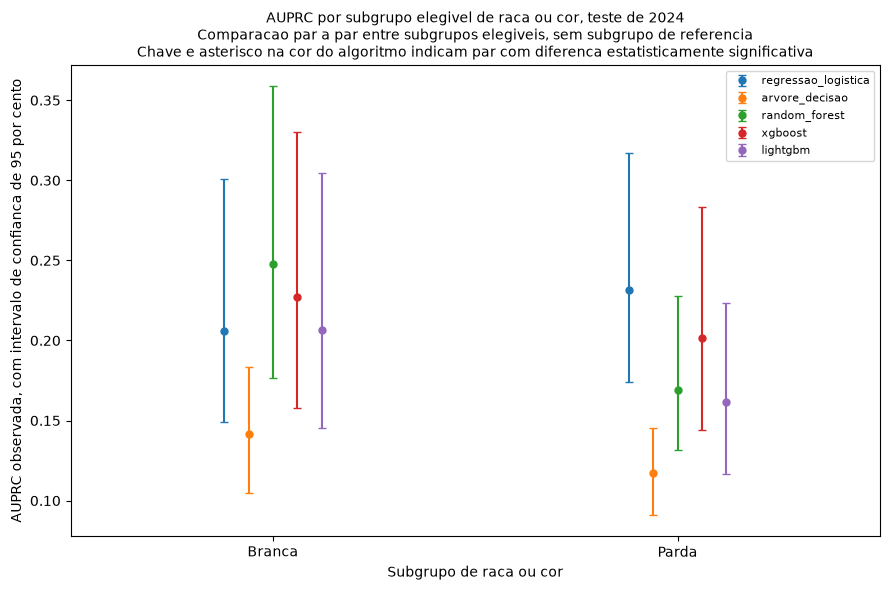

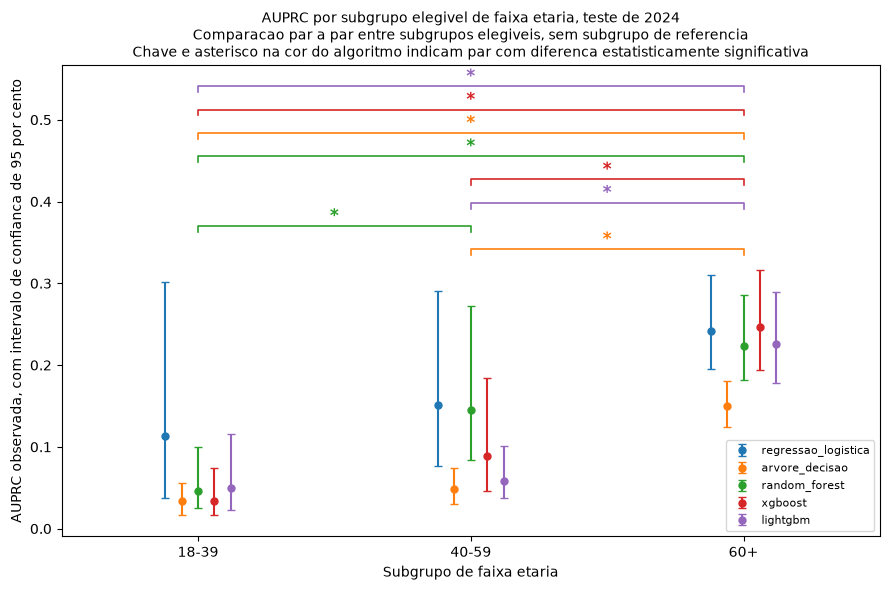

In [16]:
CORES_ALGORITMO = {
    "regressao_logistica": "tab:blue",
    "arvore_decisao": "tab:orange",
    "random_forest": "tab:green",
    "xgboost": "tab:red",
    "lightgbm": "tab:purple",
}

for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    rotulo_variavel = especificacao["rotulo_variavel"]

    subgrupos_elegiveis_ordenados = [
        especificacao["rotulos_subgrupo"][codigo_subgrupo]
        for codigo_subgrupo in especificacao["subgrupos"]
        if especificacao["rotulos_subgrupo"][codigo_subgrupo]
        in conjunto_subgrupos_elegiveis.get(nome_variavel, set())
    ]
    posicoes_subgrupo = {subgrupo: indice for indice, subgrupo in enumerate(subgrupos_elegiveis_ordenados)}

    tabela_variavel_elegivel = tabela_equidade_consolidada.loc[
        (tabela_equidade_consolidada["variavel_estratificacao"] == nome_variavel)
        & (tabela_equidade_consolidada["subgrupo"].isin(subgrupos_elegiveis_ordenados))
    ].copy()

    comparacoes_variavel_auprc = tabela_comparacoes_par_a_par.loc[
        (tabela_comparacoes_par_a_par["variavel_estratificacao"] == nome_variavel)
        & (tabela_comparacoes_par_a_par["metrica"] == "auprc")
        & (tabela_comparacoes_par_a_par["significativa"])
    ]

    numero_algoritmos = len(ALGORITMOS)
    deslocamento_maximo = 0.12
    figura, eixo = plt.subplots(figsize=(9, 6))

    valor_maximo_exibido = tabela_variavel_elegivel["auprc_ic95_superior"].astype(float).max()

    for indice_algoritmo, algoritmo in enumerate(ALGORITMOS):
        deslocamento = (indice_algoritmo - (numero_algoritmos - 1) / 2) * (
            2 * deslocamento_maximo / (numero_algoritmos - 1)
        )
        tabela_algoritmo_variavel = (
            tabela_variavel_elegivel.loc[tabela_variavel_elegivel["algoritmo"] == algoritmo]
            .set_index("subgrupo")
            .loc[subgrupos_elegiveis_ordenados]
        )

        posicoes_x = (
            np.array([posicoes_subgrupo[subgrupo] for subgrupo in subgrupos_elegiveis_ordenados]) + deslocamento
        )
        valores_auprc = tabela_algoritmo_variavel["auprc"].to_numpy(dtype=float)
        erro_inferior = valores_auprc - tabela_algoritmo_variavel["auprc_ic95_inferior"].to_numpy(dtype=float)
        erro_superior = tabela_algoritmo_variavel["auprc_ic95_superior"].to_numpy(dtype=float) - valores_auprc

        eixo.errorbar(
            posicoes_x,
            valores_auprc,
            yerr=[erro_inferior, erro_superior],
            fmt="o",
            color=CORES_ALGORITMO[algoritmo],
            label=algoritmo,
            capsize=3,
            markersize=5,
        )

    comparacoes_variavel_auprc_ordenadas = comparacoes_variavel_auprc.copy()
    comparacoes_variavel_auprc_ordenadas["amplitude_posicoes"] = [
        abs(posicoes_subgrupo[subgrupo_1] - posicoes_subgrupo[subgrupo_2])
        for subgrupo_1, subgrupo_2 in zip(
            comparacoes_variavel_auprc_ordenadas["subgrupo_1"], comparacoes_variavel_auprc_ordenadas["subgrupo_2"]
        )
    ]
    comparacoes_variavel_auprc_ordenadas = comparacoes_variavel_auprc_ordenadas.sort_values("amplitude_posicoes")

    altura_chave = valor_maximo_exibido * 1.08
    incremento_chave = valor_maximo_exibido * 0.09
    for _, comparacao in comparacoes_variavel_auprc_ordenadas.iterrows():
        posicao_1 = posicoes_subgrupo[comparacao["subgrupo_1"]]
        posicao_2 = posicoes_subgrupo[comparacao["subgrupo_2"]]
        cor_algoritmo = CORES_ALGORITMO[comparacao["algoritmo"]]

        eixo.plot(
            [posicao_1, posicao_1, posicao_2, posicao_2],
            [
                altura_chave - incremento_chave * 0.25,
                altura_chave,
                altura_chave,
                altura_chave - incremento_chave * 0.25,
            ],
            color=cor_algoritmo,
            linewidth=1.2,
        )
        eixo.text(
            (posicao_1 + posicao_2) / 2,
            altura_chave + incremento_chave * 0.08,
            "*",
            ha="center",
            va="bottom",
            color=cor_algoritmo,
            fontsize=12,
            fontweight="bold",
        )
        altura_chave += incremento_chave

    eixo.set_xticks(list(posicoes_subgrupo.values()))
    eixo.set_xticklabels(list(posicoes_subgrupo.keys()))
    eixo.set_xlim(-0.5, len(subgrupos_elegiveis_ordenados) - 0.5)
    eixo.set_xlabel(f"Subgrupo de {rotulo_variavel}")
    eixo.set_ylabel("AUPRC observada, com intervalo de confianca de 95 por cento")
    eixo.set_title(
        f"AUPRC por subgrupo elegivel de {rotulo_variavel}, teste de 2024\n"
        "Comparacao par a par entre subgrupos elegiveis, sem subgrupo de referencia\n"
        "Chave e asterisco na cor do algoritmo indicam par com diferenca estatisticamente significativa",
        fontsize=10,
    )
    eixo.legend(loc="best", fontsize=8)
    figura.tight_layout()
    figura.savefig(DIRETORIO_PLOTS / f"auprc_por_subgrupo_{nome_variavel}.png", dpi=150)
    plt.show()


## Sintese dos achados

O criterio de elegibilidade baseado na largura do intervalo de confianca de 95 por cento da ROC-AUC, exigida abaixo de 0,35 nos cinco algoritmos ao mesmo tempo, chega aos mesmos sete subgrupos elegiveis de versoes anteriores desta analise, Feminino e Masculino em sexo, Branca e Parda em raca ou cor, e 18 a 39 anos, 40 a 59 anos e 60 anos ou mais em faixa etaria.
A mudanca nesta versao nao esta na elegibilidade, e sim em como os subgrupos elegiveis sao comparados entre si: em vez de um delta contra um subgrupo de referencia fixo por variavel, a comparacao agora usa todas as diferencas par a par entre os subgrupos elegiveis de cada variavel e a amplitude entre o subgrupo de maior e o subgrupo de menor metrica, sem favorecer nenhum subgrupo a priori.

Das 50 combinacoes de par de subgrupos elegiveis, algoritmo e metrica avaliadas em `comparacoes_par_a_par.csv`, dez em sexo, dez em raca ou cor, e trinta em faixa etaria, apenas oito tem intervalo de confianca de 95 por cento que exclui zero, e as oito sao diferencas de AUPRC dentro de faixa etaria.
Nenhuma diferenca de ROC-AUC, em nenhuma das tres variaveis, e estatisticamente distinguivel de zero em nenhum dos cinco algoritmos, o mesmo padrao ja observado em versoes anteriores desta analise, agora confirmado tambem para os pares que nao existiam antes.
Em sexo, Feminino contra Masculino, nenhuma das dez diferencas, cinco de AUPRC e cinco de ROC-AUC, e significativa: o masculino tem AUPRC pontual mais alta em quatro dos cinco algoritmos e o feminino tem ROC-AUC pontual mais alta nos cinco algoritmos, mas todos os intervalos de confianca incluem zero.
Em raca ou cor, Branca contra Parda, tambem nenhuma das dez diferencas e significativa, embora a branca tenha AUPRC pontual mais alta em quatro dos cinco algoritmos e a parda tenha ROC-AUC pontual mais alta nos cinco algoritmos, o mesmo padrao qualitativo observado em sexo, sem sustentacao estatistica em nenhuma das duas variaveis.

Em faixa etaria, a diferenca de AUPRC entre 18 a 39 anos e 60 anos ou mais e significativa em quatro dos cinco algoritmos, arvore de decisao, diferenca de -0,117 com intervalo de confianca de -0,151 a -0,084, random forest, -0,178 com intervalo de -0,241 a -0,112, xgboost, -0,213 com intervalo de -0,282 a -0,147, e lightgbm, -0,176 com intervalo de -0,241 a -0,094, mas nao na regressao logistica, cujo intervalo de -0,236 a 0,052 inclui zero.
A diferenca de AUPRC entre 18 a 39 anos e 40 a 59 anos e significativa apenas no random forest, -0,100 com intervalo de -0,221 a -0,017.
A diferenca de AUPRC entre 40 a 59 anos e 60 anos ou mais, o par que nao existia na versao anterior desta analise porque nenhum dos dois subgrupos era a referencia de faixa etaria, e significativa em tres dos cinco algoritmos, arvore de decisao, -0,101 com intervalo de -0,137 a -0,068, xgboost, -0,158 com intervalo de -0,242 a -0,054, e lightgbm, -0,168 com intervalo de -0,232 a -0,103, mas nao no random forest, cujo intervalo de -0,162 a 0,047 inclui zero, nem na regressao logistica.
Em todos os oito casos significativos, o subgrupo de maior idade tem AUPRC pontual mais alta do que o subgrupo de menor idade do par, nunca o contrario.

A amplitude entre o subgrupo de maior e o subgrupo de menor metrica, em `amplitude_por_variavel.csv`, reproduz essa mesma direcao: em faixa etaria, a AUPRC tem 60 anos ou mais como subgrupo de maior valor e 18 a 39 anos como subgrupo de menor valor nos cinco algoritmos, com amplitude pontual entre 0,117 e 0,213, enquanto a identidade do subgrupo de maior ROC-AUC varia entre os tres subgrupos conforme o algoritmo, com amplitude pontual bem menor, entre 0,061 e 0,095, reforcando que essa metrica nao mostra nenhum padrao etario consistente.
Em sexo e em raca ou cor, a amplitude de AUPRC fica entre 0,019 e 0,079 conforme o algoritmo, e a amplitude de ROC-AUC fica entre 0,001 e 0,055, sempre menor do que a menor amplitude de AUPRC observada em faixa etaria.
Como a amplitude e a diferenca entre um maximo e um minimo, ela e sempre maior ou igual a zero por construcao, e por isso o intervalo de confianca da amplitude exclui zero nas 30 linhas de `amplitude_por_variavel.csv`, inclusive nas combinacoes de sexo, raca ou cor, e ROC-AUC de faixa etaria em que a diferenca par a par com sinal correspondente nao e significativa.
A coluna `significativa` da amplitude mede se a dispersao observada entre os subgrupos elegiveis e distinguivel de uma dispersao nula, nao se um subgrupo especifico supera outro, e por isso a tabela de comparacoes par a par, nao a de amplitude, deve orientar qualquer afirmacao sobre quais subgrupos diferem entre si.

A ressalva sobre AUPRC e prevalencia de obito, apresentada antes desta sintese, e diretamente relevante para o unico padrao que sobrevive ao bootstrap: a faixa de 60 anos ou mais tem a maior prevalencia de obito entre os subgrupos elegiveis, 11,85 por cento, contra 3,99 por cento em 40 a 59 anos e 1,94 por cento em 18 a 39 anos, e e tambem o subgrupo de maior AUPRC em todos os cinco algoritmos, a mesma ordem da prevalencia.
Isso nao invalida a diferenca de AUPRC observada, mas significa que parte dela, de magnitude nao quantificada por este notebook, pode vir do piso teorico da metrica em vez de uma diferenca real na capacidade de ordenacao do modelo, uma distincao que o ROC-AUC, livre desse piso, nao sustenta para nenhum par de faixa etaria.
A capacidade de discriminacao de risco, medida pelo ROC-AUC, portanto nao mostra nenhuma diferenca estatisticamente distinguivel de zero entre subgrupos elegiveis em nenhuma das tres variaveis de estratificacao, com os dados e os modelos atuais, a mesma conclusao de versoes anteriores desta analise, agora obtida sem escolher nenhum subgrupo de referencia.